# Code and data for *"Information-geometry-driven graph sequential growth"*

---

# Part 3: Experiments on the Riboflavin data 

## Contents
 - [A. Data preprocessing (variable selection and nonparanormal transformation)](#sec3A)
 - [B. Experiment for Figures 8 and 9 (Section 6.3)](#sec3B)
 - [C. Experiment for Figure 10 (Section 6.3)](#sec3C)

<a id="sec3A"></a>
## A. Data preprocessing (variable selection and nonparanormal transformation)

Observe that after the nonparanormal transformation, we can assume that the data arise from a centred random vector.    


In [1]:
import numpy as np
import pandas as pd
from scipy.stats import norm

import all_solvers as sol
import all_experiments as exp

The data set `riboflavin.csv` is provided in the `Data` folder; it can be found on the [CRAN archive of the package hdi](https://cran.r-project.org/src/contrib/Archive/hdi/), for instance.  

In [2]:
## 1. Load the data set 
df_raw = pd.read_csv("Data/riboflavin.csv")

## 2. Drop target/index columns to isolate gene expressions (n = 71, p = 4088)
drop_cols = [c for c in df_raw.columns if c in ['y', 'Unnamed: 0', 'q_RIBFLV']]
df_genes = df_raw.drop(columns=drop_cols)

X_raw = df_genes.values.astype(float)
n_samples, n_features = X_raw.shape

## 3. Select d = 100 genes with highest empirical variance
variances = np.var(X_raw, axis=0, ddof=1)
top_100_idx = np.argsort(variances)[-100:][::-1]

X_100 = X_raw[:, top_100_idx]
gene_names_100 = df_genes.columns[top_100_idx].tolist()

## 4. Nonparanormal (NPN) transformation
def nonparanormal_transform(X, truncate=True):
    n, d = X.shape
    X_npn = np.zeros_like(X, dtype=float)
    delta_n = 1.0 / (4.0 * (n ** 0.25) * np.sqrt(np.pi * np.log(n)))
    
    for j in range(d):
        ranks = pd.Series(X[:, j]).rank(method='average').values
        F_hat = ranks / n
        if truncate:
            F_hat = np.clip(F_hat, delta_n, 1.0 - delta_n)
        else:
            F_hat = ranks / (n + 1.0)
        X_npn[:, j] = norm.ppf(F_hat)
        
    return X_npn

X_npn = nonparanormal_transform(X_100, truncate=True)

<a id="sec3B"></a>
## B. Experiment for Figures 8 and 9 (Section 6.3)

> **Computational note:** For $d=100$, each full GSL growth can take a few seconds. To reduce runtime, reduce the number of Monte Carlo repetitions `n_reps`. 

In [3]:
## 1. Run experiment for Figure 8, n_reps Monte Carlo repetitions  
results_fig8 = exp.run_experiment_fig8(
    data=X_npn,
    frac_sample=0.5,
    #n_reps=500,     
    n_reps=100,      # use only 100 repetitions    
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3,
    RP_coeff=1e-6,
    n_jobs=-1,       # allocate maximum number of threads
    seed=1
)

Starting Figure 8 Subsampling Benchmark:
  Total Data Shape : (71, 100)
  Subsample Size   : 36 (frac=0.5)
  Max Iterations   : 4950
  Repetitions      : 100
  Parallel Jobs    : -1


Subsampling (n=36): 100%|████████████████████| 100/100 [10:38<00:00,  6.38s/it]


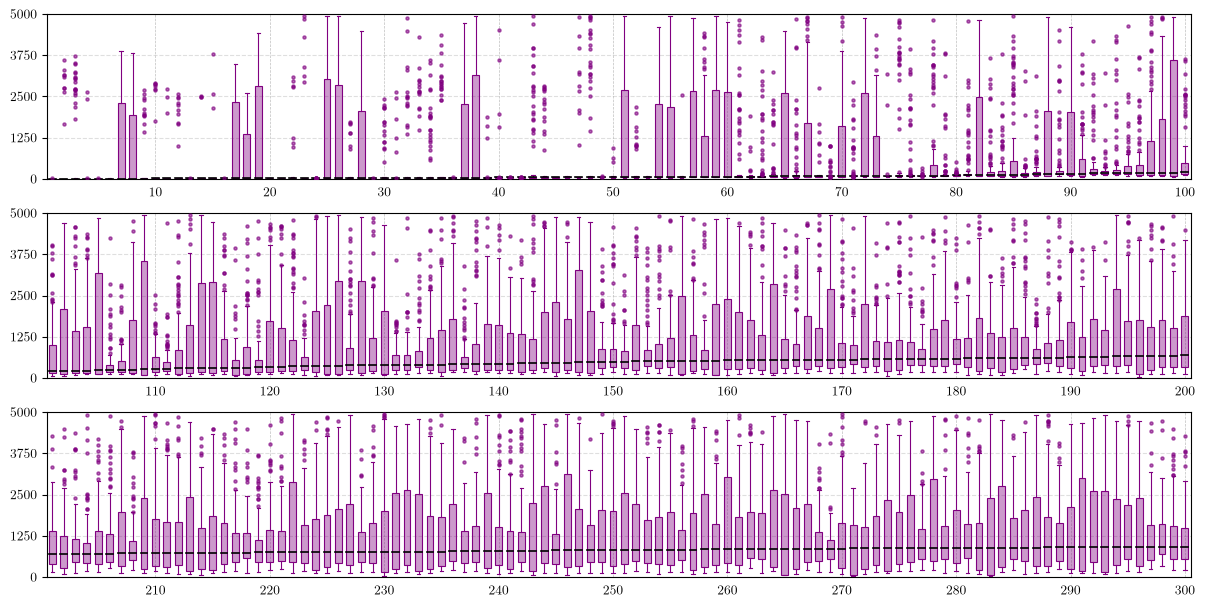

In [4]:
## 2. Render Figure 8
fig8 = exp.plot_figure_8(
    results=results_fig8,
    top_k=300,
    num_splits=3,
    max_y=5000,
    font_scale=1.0
    #save_path="Figures/Figure_8.pdf"
)

In [5]:
## 3. Extract median activation rank from results_fig8
edge_summary = []
for edge, positions in results_fig8['edge_positions'].items():
    if len(positions) > 0:
        edge_summary.append({
            'edge': (min(edge[0], edge[1]), max(edge[0], edge[1])),
            'median_rank': float(np.median(positions))
        })

## 4. Order edges by median activation rank ascending
edge_summary.sort(key=lambda x: x['median_rank'])
activ_rank_median = [item['edge'] for item in edge_summary]

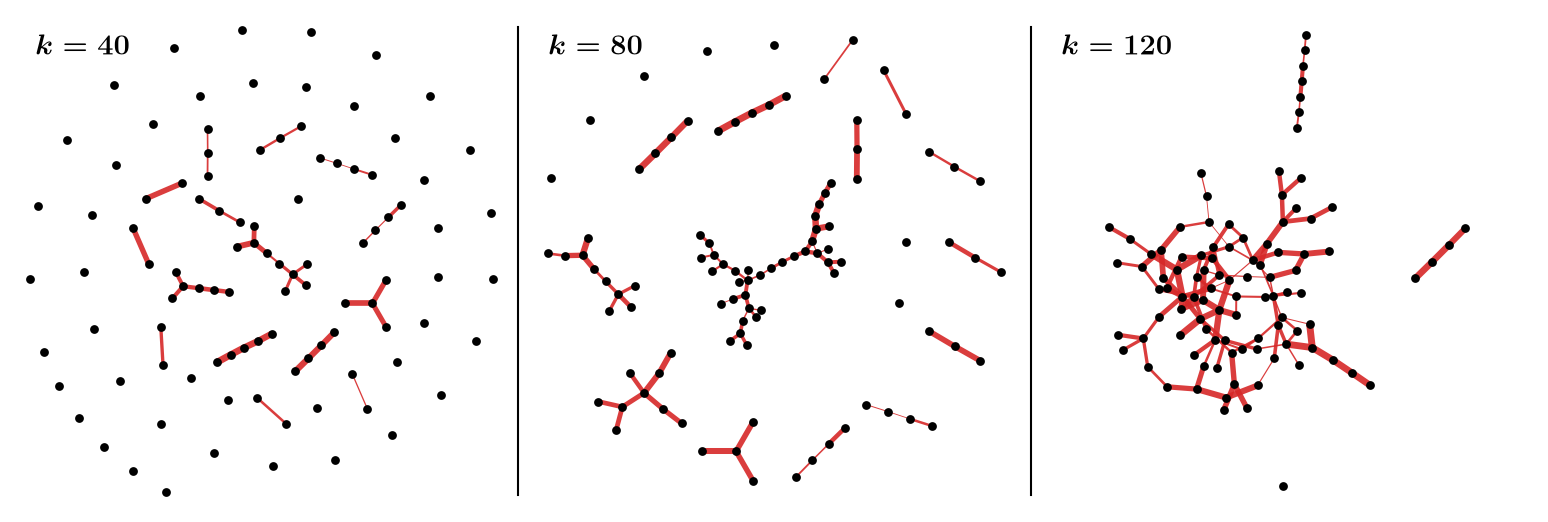

In [6]:
## 5. Render Figure 9
fig9 = exp.plot_graphical_model_grid(
    activ_rank=activ_rank_median,
    k_vals=[40, 80, 120],
    isolated_vrtx=True,
    thickness_range=(0.6, 5.0),
    font_scale=1.5 
    #save_path="Figures/Figure_9.pdf"
)

<a id="sec3C"></a>
## C. Experiment for Figure 10 (Section 6.3)

In [7]:
## 1. Compute the ridge-penalised sample covariance (full data)
n_samp, dim = X_npn.shape
RP_coeff = 1e-6 # ridge penalty coeff
Sigma_hat = (X_npn.T @ X_npn) / n_samp        # zero-mean case
RP_val = np.mean(np.diag(Sigma_hat)) * RP_coeff
S_ribo = Sigma_hat + RP_val * np.eye(dim)     # matrix S

## 2. Run GSL (k_max=120) once on the covariance matrix S_ribo for full data set
gsl_full_out = sol.GSL_solver(
    S=S_ribo,
    max_iter=120,
    true_P=None,
    activ_mul=0.3,
    activ_add=10,
    tau_improv=1e-3
)

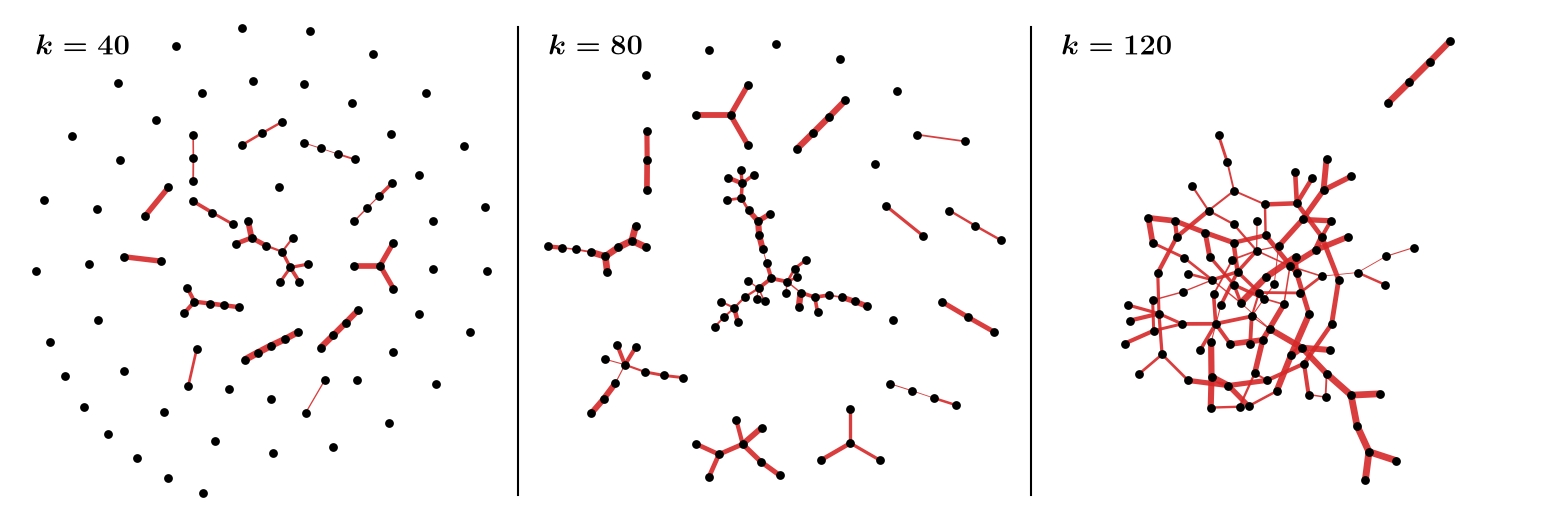

In [8]:
## 3. Render Figure 10
GSL_rank = list(dict.fromkeys((min(u, v), max(u, v)) for u, v in gsl_full_out['evo_edge']))

fig10 = exp.plot_graphical_model_grid(
    activ_rank=GSL_rank,
    k_vals=[40, 80, 120],
    isolated_vrtx=True,
    thickness_range=(0.6, 5.0),
    font_scale=1.5
    #save_path="Figures/Figure_10.pdf"
)